In [1]:
import numpy as np
import xarray as xr
import rioxarray as rxr
import glob
from scipy import interpolate

In [2]:
DEM_files = sorted(glob.glob('/glade/derecho/scratch/jstarfeldt/uhminicubes/hresgrid/DEM/KATL/*'))
DEM_files

['/glade/derecho/scratch/jstarfeldt/uhminicubes/hresgrid/DEM/KATL/N33W084.tif',
 '/glade/derecho/scratch/jstarfeldt/uhminicubes/hresgrid/DEM/KATL/N33W085.tif',
 '/glade/derecho/scratch/jstarfeldt/uhminicubes/hresgrid/DEM/KATL/N34W084.tif',
 '/glade/derecho/scratch/jstarfeldt/uhminicubes/hresgrid/DEM/KATL/N34W085.tif']

In [3]:
ds_DEM = xr.combine_by_coords([rxr.open_rasterio(file) for file in DEM_files])
ds_DEM

<xarray.DataArray (band: 1, y: 2402, x: 2402)> Size: 12MB
array([[[291, 287, 285, ..., 571, 575, 572],
        [289, 284, 285, ..., 552, 554, 566],
        [293, 302, 294, ..., 531, 542, 561],
        ...,
        [221, 217, 207, ..., 101,  95,  96],
        [213, 206, 205, ..., 105, 104,  98],
        [220, 209, 204, ..., 109, 110, 106]]],
      shape=(1, 2402, 2402), dtype=int16)
Coordinates:
  * band         (band) int64 8B 1
  * x            (x) float64 19kB -85.0 -85.0 -85.0 -85.0 ... -83.0 -83.0 -83.0
  * y            (y) float64 19kB 35.0 35.0 35.0 35.0 ... 33.0 33.0 33.0 33.0
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

In [5]:
dsL = xr.open_dataset('/gdex/data/d539393/high_resolution/grid/hresgrid_KATL_latlon.nc')
dsL

<xarray.Dataset> Size: 144MB
Dimensions:      (y: 3000, x: 3000)
Coordinates:
  * x            (x) float64 24kB 7.031e+05 7.032e+05 ... 7.931e+05 7.931e+05
  * y            (y) float64 24kB 3.698e+06 3.698e+06 ... 3.788e+06 3.788e+06
    spatial_ref  int32 4B ...
Data variables:
    latitude     (y, x) float64 72MB ...
    longitude    (y, x) float64 72MB ...
Attributes:
    AREA_OR_POINT:  Area
    title:          Latitude and Longitude coordinates of high-resolution gri...
    institution:    University of Maryland, College Park

In [7]:
latlon_pts_hresgrid = np.stack([dsL['longitude'], dsL['latitude']], axis=-1)
latlon_pts_hresgrid

array([[[-84.81590558,  33.3991054 ],
        [-84.81558321,  33.39909972],
        [-84.81526084,  33.39909405],
        ...,
        [-83.85022854,  33.37833903],
        [-83.8499065 ,  33.37833085],
        [-83.84958446,  33.37832267]],

       [[-84.81589881,  33.3993758 ],
        [-84.81557644,  33.39937012],
        [-84.81525407,  33.39936444],
        ...,
        [-83.85021879,  33.37860922],
        [-83.84989675,  33.37860104],
        [-83.84957471,  33.37859286]],

       [[-84.81589204,  33.39964619],
        [-84.81556967,  33.39964052],
        [-84.8152473 ,  33.39963484],
        ...,
        [-83.85020904,  33.3788794 ],
        [-83.84988699,  33.37887122],
        [-83.84956495,  33.37886304]],

       ...,

       [[-84.79521149,  34.20942571],
        [-84.79488607,  34.20941986],
        [-84.79456065,  34.209414  ],
        ...,
        [-83.82041641,  34.18801812],
        [-83.82009133,  34.18800969],
        [-83.81976626,  34.18800125]],

       [[-84.79

In [8]:
min_lon = np.min(latlon_pts_hresgrid[:, :, 0])-0.1
max_lon = np.max(latlon_pts_hresgrid[:, :, 0])+0.1
min_lat = np.min(latlon_pts_hresgrid[:, :, 1])-0.1
max_lat = np.max(latlon_pts_hresgrid[:, :, 1])+0.1

In [9]:
mask = (
    (ds_DEM.y >= min_lat) &
    (ds_DEM.y <= max_lat) &
    (ds_DEM.x >= min_lon) &
    (ds_DEM.x <= max_lon)
)

In [10]:
ds_DEM = ds_DEM.where(
    mask,
    drop=True
)
ds_DEM

<xarray.DataArray (band: 1, y: 1239, x: 1437)> Size: 7MB
array([[[284., 296., 308., ..., 282., 293., 296.],
        [288., 308., 325., ..., 294., 293., 297.],
        [295., 309., 321., ..., 304., 309., 310.],
        ...,
        [229., 231., 228., ..., 203., 209., 207.],
        [235., 233., 230., ..., 205., 213., 217.],
        [228., 234., 231., ..., 203., 209., 213.]]],
      shape=(1, 1239, 1437), dtype=float32)
Coordinates:
  * band         (band) int64 8B 1
  * x            (x) float64 11kB -84.92 -84.92 -84.91 ... -83.72 -83.72 -83.72
  * y            (y) float64 10kB 34.31 34.31 34.31 34.31 ... 33.28 33.28 33.28
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

In [13]:
DEM_values = ds_DEM[0].values.flatten()
DEM_values

array([284., 296., 308., ..., 203., 209., 213.],
      shape=(1780443,), dtype=float32)

In [11]:
y, x = np.meshgrid(ds_DEM['y'], ds_DEM['x'])
latlons = np.stack((x, y)).T.reshape(-1, 2)
latlons

array([[-84.91583333,  34.30916667],
       [-84.915     ,  34.30916667],
       [-84.91416667,  34.30916667],
       ...,
       [-83.72166667,  33.27833333],
       [-83.72083333,  33.27833333],
       [-83.72      ,  33.27833333]], shape=(1780443, 2))

In [14]:
DEM = interpolate.griddata(latlons, DEM_values, latlon_pts_hresgrid, method='nearest')
DEM

array([[276., 276., 281., ..., 168., 168., 168.],
       [276., 276., 281., ..., 168., 168., 159.],
       [285., 285., 273., ..., 166., 166., 159.],
       ...,
       [244., 244., 245., ..., 309., 309., 309.],
       [242., 242., 245., ..., 309., 309., 309.],
       [242., 242., 245., ..., 309., 309., 309.]], shape=(3000, 3000))

In [16]:
import matplotlib.pyplot as plt

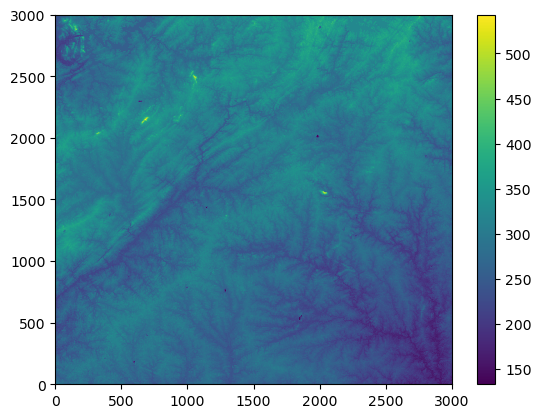

In [17]:
cb = plt.pcolormesh(DEM)
plt.colorbar(cb)